# Multiple Linear Regression: What Predicts Final Exam Scores?

**Template notebook.** Replace the dataset, research question and variable names with your own; keep the structure.

## 1. Research question

**Which student habits and characteristics predict final exam scores, and which matter most?**

Sub-questions:
- How much does one extra hour of weekly study change the expected score, holding other factors constant?
- Do sleep, attendance and study groups matter once prior GPA is taken into account?
- Is working a part-time job associated with lower scores?

**Why linear regression?** The outcome (`final_exam_score`, 0–100) is a continuous number, and we want to estimate how each predictor changes it while holding the others constant.

## 2. The dataset

`student_performance.csv`: 600 students, one row per student.

| Column | Type | Meaning |
| --- | --- | --- |
| student_id | text | Student ID (not used in the model) |
| major | category | Business, Data Science, Engineering, Health, Humanities |
| study_hours_week | numeric | Hours spent studying per week |
| attendance_pct | numeric | % of classes attended |
| prior_gpa | numeric | GPA before the course (0–4) |
| sleep_hours | numeric | Average hours of sleep per night |
| works_part_time | 0/1 | 1 = has a part-time job |
| work_hours_week | numeric | Hours worked per week (0 if no job) |
| commute_minutes | numeric | One-way commute time, minutes |
| study_group | 0/1 | 1 = attends a study group |
| first_generation | 0/1 | 1 = first-generation college student |
| final_exam_score | numeric | Final exam score, 0–100 (**target for linear regression**) |
| performance_level | category | Low / Medium / High (**target for multiclass logistic regression**) |

*The data is simulated for teaching; it is realistic but not real.*

#### Cell: Import the libraries

**What this cell does.** Loads the Python packages the notebook needs and sets display options. Run this cell first, every time you open the notebook.

**The code, line by line:**
- `pandas` (as `pd`): tables of data (DataFrames) — reading CSVs, filtering, grouping, summarizing.
- `numpy` (as `np`): fast math on numbers and arrays (square roots, logs, exponentials).
- `matplotlib.pyplot` (as `plt`) and `seaborn` (as `sns`): plotting. Seaborn builds nicer statistical charts on top of matplotlib.
- `statsmodels.api` (as `sm`) and `statsmodels.formula.api` (as `smf`): statistical models. `smf` lets us write models as formulas like `y ~ x1 + x2`, the same style used in R.
- `variance_inflation_factor`: measures multicollinearity (Section 7).
- `train_test_split` from scikit-learn: splits the data into training and test sets.
- `pd.set_option("display.max_columns", None)` shows every column instead of hiding some with `...`.
- `sns.set_theme(style="whitegrid")` gives all charts a clean white background with light grid lines.

**Why it matters.** If an import fails with `ModuleNotFoundError`, the package is not installed. Install it with `pip install statsmodels seaborn scikit-learn` (or `%pip install ...` inside the notebook) and run the cell again.

**How to read the output.** This cell prints nothing when it works. No output = success.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 3. Exploratory data analysis (EDA)

### 3.1 First look

#### Cell: Load the dataset

**What this cell does.** Reads the CSV file into a DataFrame called `df`, prints its size, and shows the first five rows.

**The code, line by line:**
- `pd.read_csv("student_performance.csv")` reads the file. It must be in the **same folder** as the notebook; otherwise give the full path, e.g. `pd.read_csv("data/student_performance.csv")`.
- `df.shape` returns `(rows, columns)`.
- `df.head()` shows the first 5 rows (`df.head(10)` shows 10). Because it is the last line of the cell, Jupyter displays it automatically.

**Why it matters.** Always look at the raw data before analyzing it. Check that columns loaded correctly, values look sensible, and you understand what one row represents.

**How to read the output.** The shape should be **(600, 13)**: 600 students and 13 columns. Each row is one student. `NaN` in the table means a missing value.

In [2]:
df = pd.read_csv("student_performance.csv")
print(df.shape)
df.head()

(600, 13)


,student_id,major,study_hours_week,attendance_pct,prior_gpa,sleep_hours,works_part_time,work_hours_week,commute_minutes,study_group,first_generation,final_exam_score,performance_level
0,S0001,Business,6.9,NaN,2.21,5.0,1,22.0,30.0,1,0,51.4,Low
1,S0002,Engineering,8.5,83.0,3.09,7.0,1,16.0,8.0,1,1,70.9,Medium
2,S0003,Engineering,12.0,100.0,2.76,6.3,1,15.0,8.0,1,1,74.6,Medium
3,S0004,Data Science,6.6,77.0,2.58,6.2,0,0.0,74.0,1,1,76.0,Medium
4,S0005,Data Science,5.2,90.0,3.18,5.2,0,0.0,20.0,1,0,80.5,Medium


#### Cell: Column types and non-missing counts

**What this cell does.** Lists every column with its data type and how many non-missing values it has.

**The code, line by line:**
- `df.info()` prints the column name, the **Non-Null Count** (values that are not missing) and the **Dtype** (data type).
- Common types: `int64` (whole numbers), `float64` (decimals, and also whole-number columns that contain missing values), `object` or `str` (text).

**Why it matters.** Wrong data types cause errors later. For example, a number column read as text (because of a stray symbol like "N/A") cannot be averaged or used in a model.

**How to read the output.** All 600 rows are present. Four columns have fewer than 600 non-null values, which means they have missing data: `attendance_pct` (588), `prior_gpa` (591), `sleep_hours` (573) and `commute_minutes` (582). `major`, `student_id` and `performance_level` are text; the rest are numeric. The 0/1 columns (`works_part_time`, `study_group`, `first_generation`) are stored as integers, which is what the models need.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         600 non-null    object 
 1   major              600 non-null    object 
 2   study_hours_week   600 non-null    float64
 3   attendance_pct     588 non-null    float64
 4   prior_gpa          591 non-null    float64
 5   sleep_hours        573 non-null    float64
 6   works_part_time    600 non-null    int64  
 7   work_hours_week    600 non-null    float64
 8   commute_minutes    582 non-null    float64
 9   study_group        600 non-null    int64  
 10  first_generation   600 non-null    int64  
 11  final_exam_score   600 non-null    float64
 12  performance_level  600 non-null    object 
dtypes: float64(7), int64(3), object(3)
memory usage: 61.1+ KB


#### Cell: Summary statistics

**What this cell does.** Computes the count, mean, standard deviation, minimum, quartiles and maximum of every numeric column.

**The code, line by line:**
- `df.describe()` summarizes numeric columns only (text columns are skipped).
- `.round(2)` rounds to 2 decimals so the table is easier to read.
- **25% / 50% / 75%** are the quartiles; 50% is the **median**.

**Why it matters.** Summary statistics reveal typos and impossible values (a GPA of 7, negative hours), show the scale of each variable, and hint at skew: when the mean is far from the median, the distribution is lopsided.

**How to read the output.** Values are all in sensible ranges: study hours 1.2–29.1 per week (mean 8.8), attendance 57–100%, prior GPA 1.5–4.0 (mean 3.0), sleep 4–10 hours (mean 7.0), commute 1–117 minutes (mean 24, median 20), final exam score 41.8–100 (mean 74.4, SD 9.9). Commute and study hours have means above their medians, so they are **right-skewed** (a few students with very long commutes or many study hours). For 0/1 columns the mean is the share of 1s: 47% work part-time, 36% are in a study group, 32% are first-generation.

In [4]:
df.describe().round(2)

,study_hours_week,attendance_pct,prior_gpa,sleep_hours,works_part_time,work_hours_week,commute_minutes,study_group,first_generation,final_exam_score
count,600.00,588.00,591.00,573.00,600.00,600.00,582.00,600.00,600.00,600.00
mean,8.77,84.39,2.99,7.01,0.47,8.69,24.18,0.36,0.32,74.43
std,4.22,9.18,0.51,1.08,0.50,10.29,17.19,0.48,0.47,9.91
min,1.20,57.00,1.50,4.00,0.00,0.00,1.00,0.00,0.00,41.80
25%,5.60,78.00,2.62,6.20,0.00,0.00,12.00,0.00,0.00,67.88
50%,8.15,84.00,3.03,7.00,0.00,0.00,20.00,0.00,0.00,74.70
75%,11.30,91.00,3.36,7.70,1.00,18.25,32.00,1.00,1.00,80.70
max,29.10,100.00,4.00,10.00,1.00,35.00,117.00,1.00,1.00,100.00


### 3.2 Missing values and duplicates

#### Cell: Count missing values

**What this cell does.** Builds a small table with the number and percentage of missing values in each column, and shows only columns with at least one gap.

**The code, line by line:**
- `df.isna()` gives True where a value is missing; `.sum()` counts the Trues per column (True counts as 1).
- `df.isna().mean() * 100` is the **percentage** missing (the mean of True/False is the share of Trues).
- `missing[missing.missing > 0]` keeps only columns with gaps; `.sort_values(..., ascending=False)` puts the worst first.

**Why it matters.** Models in statsmodels silently **drop every row with a missing value** in any variable used. Knowing where the gaps are lets you decide deliberately how to handle them instead of losing data without noticing.

**How to read the output.** Four columns have gaps: `sleep_hours` 27 (4.5%), `commute_minutes` 18 (3.0%), `attendance_pct` 12 (2.0%) and `prior_gpa` 9 (1.5%). All are below 5%, which is small. A common rule of thumb: under about 5% missing, simple fixes like filling with the median are reasonable; above 20–30%, think harder about *why* data is missing.

In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing[missing.missing > 0].sort_values("missing", ascending=False)

,missing,percent
sleep_hours,27,4.5
commute_minutes,18,3.0
attendance_pct,12,2.0
prior_gpa,9,1.5


#### Cell: Plot the missing values

**What this cell does.** Draws a horizontal bar chart of the percentage missing per column.

**The code, line by line:**
- `.plot(kind="barh")` makes horizontal bars directly from the pandas table.
- `plt.xlabel` and `plt.title` label the chart; `plt.show()` displays it.

**Why it matters.** A chart makes it easy to spot which variables have the most gaps, which helps when there are many columns.

**How to read the output.** Sleep has the longest bar (4.5%), followed by commute, attendance and GPA. No column comes close to a level that would worry us.

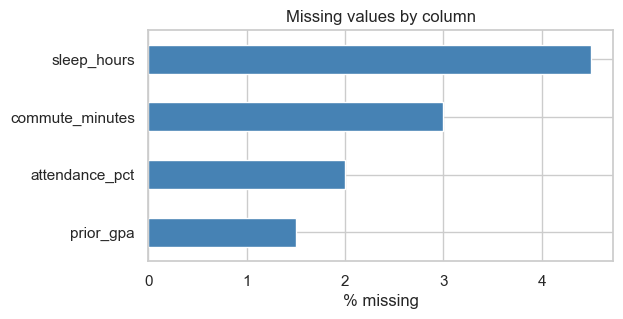

In [6]:
missing_cols = missing[missing.missing > 0].sort_values("missing")
missing_cols["percent"].plot(kind="barh", color="steelblue", figsize=(6, 3))
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.show()

#### Cell: Check duplicates and categories

**What this cell does.** Counts duplicated rows and duplicated student IDs, then lists how many students are in each major.

**The code, line by line:**
- `df.duplicated().sum()` counts rows that are exact copies of an earlier row.
- `df.student_id.duplicated().sum()` counts repeated IDs (the same student entered twice, even if other values differ).
- `df["major"].value_counts()` counts each category, largest first.

**Why it matters.** Duplicates would make some students count twice and bias the results. Category counts show whether every group is large enough to analyze; a category with only a handful of students gives unreliable estimates.

**How to read the output.** There are **0 duplicate rows and 0 duplicate IDs**. Majors are reasonably balanced: Business 143, Engineering 125, Data Science 122, Health 116, Humanities 94. Every group has enough students.

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student IDs:", df.student_id.duplicated().sum())
print()
print(df["major"].value_counts())

Duplicate rows: 0
Duplicate student IDs: 0

major
Business        143
Engineering     125
Data Science    122
Health          116
Humanities       94
Name: count, dtype: int64


**What we see:** four columns have gaps (sleep, commute, attendance and GPA), each under 5%. There are no duplicate rows or IDs. We will handle the gaps in Section 4.

### 3.3 The target: final exam score

#### Cell: Distribution of the target

**What this cell does.** Shows the final exam scores as a histogram (left) and a boxplot (right), then prints their summary statistics.

**The code, line by line:**
- `plt.subplots(1, 2, ...)` makes two side-by-side panels.
- `sns.histplot(..., bins=30, kde=True)` splits scores into 30 bars and adds a smooth curve.
- `sns.boxplot(x=...)`: the box spans the middle 50% of scores (25th to 75th percentile), the line inside is the median, the whiskers reach the typical range, and dots beyond them are possible outliers.
- `df["final_exam_score"].describe()` gives the numeric summary.

**Why it matters.** Linear regression models the **mean** of the target. It works best when the target is continuous and not extremely skewed, and it helps to know the typical value and spread before judging how large an effect is.

**How to read the output.** Scores are roughly bell-shaped and centered near **75** (mean 74.4, median 74.7, SD 9.9), ranging from 41.8 to 100. Skew is about zero, so no transformation is needed. Six scores appear as dots on the boxplot (four very low, two very high); they are plausible values, not errors. Keep the SD of about 10 points in mind: an effect of 3–4 points is a meaningful fraction of the spread.

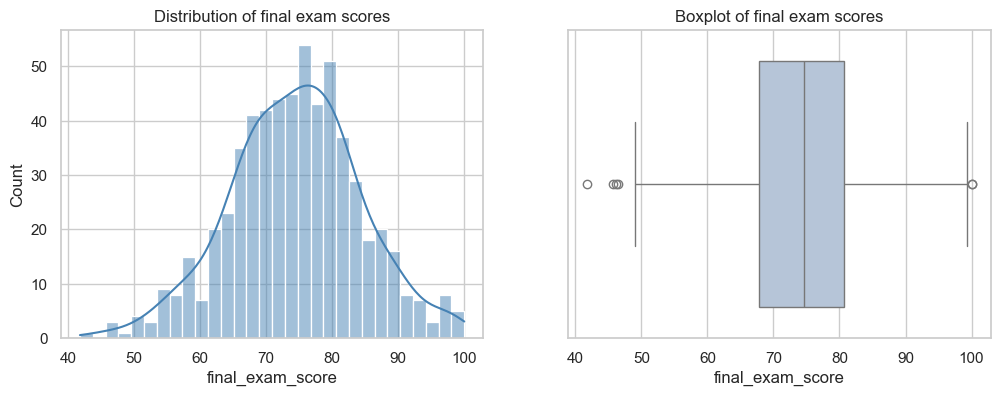

count    600.00
mean      74.43
std        9.91
min       41.80
25%       67.88
50%       74.70
75%       80.70
max      100.00
Name: final_exam_score, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["final_exam_score"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of final exam scores")
sns.boxplot(x=df["final_exam_score"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("Boxplot of final exam scores")
plt.show()
df["final_exam_score"].describe().round(2)

### 3.4 The predictors

#### Cell: Define groups of columns

**What this cell does.** Stores the names of the numeric and the 0/1 (binary) predictors in two lists so later cells can loop over them.

**The code, line by line:**
- `numeric_cols`: the six continuous predictors (hours, %, GPA, minutes).
- `binary_cols`: the three yes/no predictors coded 0/1.

**Why it matters.** Writing the lists once avoids typos and makes the notebook easy to reuse: **to adapt the template, change these lists** to your own column names.

**How to read the output.** Nothing is printed.

In [9]:
numeric_cols = ["study_hours_week", "attendance_pct", "prior_gpa", "sleep_hours",
                "work_hours_week", "commute_minutes"]
binary_cols = ["works_part_time", "study_group", "first_generation"]

#### Cell: Distributions of the numeric predictors

**What this cell does.** Draws a histogram with a smooth density curve for each of the six numeric predictors, in a 2 × 3 grid.

**The code, line by line:**
- `plt.subplots(2, 3, figsize=(14, 7))` creates a figure with 6 panels; `axes.flat` lets us loop through them.
- `zip(axes.flat, numeric_cols)` pairs each panel with one column.
- `sns.histplot(..., kde=True)` draws the histogram plus a **kernel density estimate** (the smooth curve).
- `plt.tight_layout()` stops titles and labels from overlapping.

**Why it matters.** Shape matters: skewed variables, outliers and odd spikes can affect a model. Distributions also help you describe the sample in plain words.

**How to read the output.** Attendance, GPA and sleep are roughly symmetric. **Study hours** (skew 0.9) and especially **commute** (skew 1.4) are right-skewed, with long tails of high values. **Work hours** has a big spike at 0 (the 53% of students without a job) and a separate hump around 15–25 hours for those who work. Regression does **not** require predictors to be normally distributed, but this spike comes back in the assumption checks.

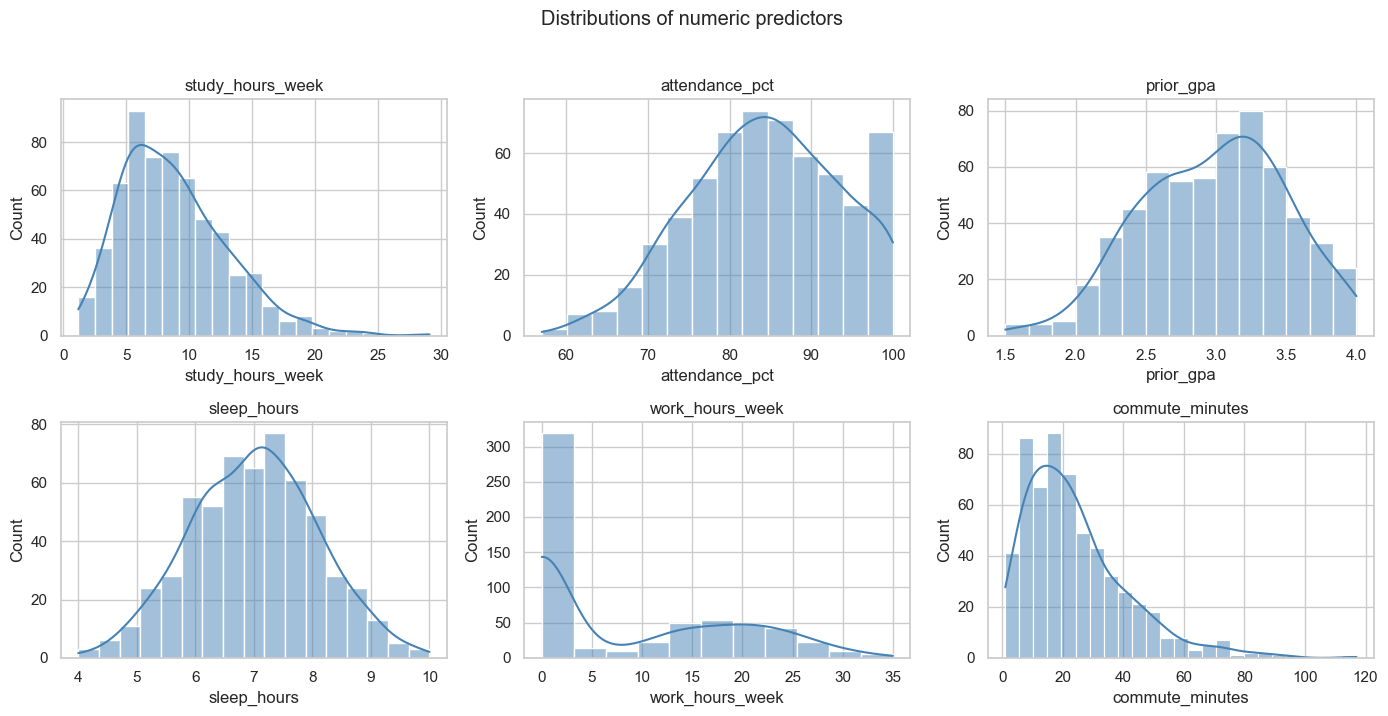

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distributions of numeric predictors", y=1.02)
plt.tight_layout()
plt.show()

#### Cell: Correlation heatmap

**What this cell does.** Computes the correlation between every pair of numeric variables (including the target) and shows them as a colored grid.

**The code, line by line:**
- `.corr()` calculates the **Pearson correlation** *r*, from −1 (perfect negative straight-line relationship) through 0 (none) to +1 (perfect positive).
- `sns.heatmap(..., annot=True, fmt=".2f")` colors each cell and writes the value with 2 decimals.
- `cmap="coolwarm", center=0` makes positive correlations red, negative ones blue and zero white.

**Why it matters.** Two uses: (1) the **target row** previews which predictors are related to scores; (2) correlations **between predictors** warn about multicollinearity (very high values, roughly above 0.8, mean two predictors carry the same information).

**How to read the output.** Correlations with the final exam score: study hours **0.47**, prior GPA **0.37**, attendance **0.32**, study group 0.17, sleep 0.16, first-generation −0.05, commute −0.09, works part-time −0.10, work hours −0.12. Predictors are almost uncorrelated with each other, **except `works_part_time` and `work_hours_week` (r = 0.90)**, which measure the same thing; that is why we drop one in Section 4. Correlation looks at one predictor at a time; the regression will estimate each effect while holding the others constant.

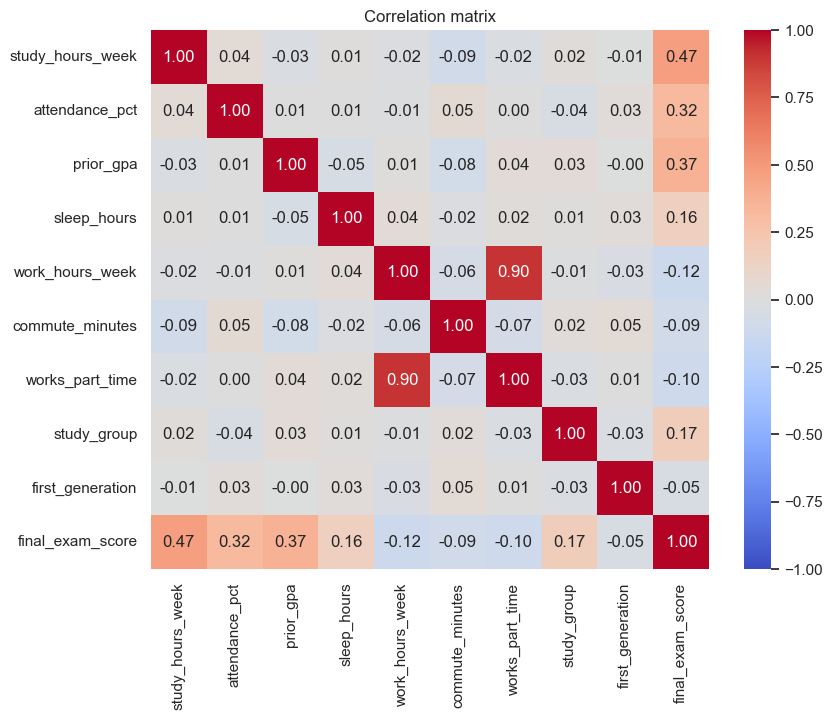

In [11]:
corr = df[numeric_cols + binary_cols + ["final_exam_score"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

#### Cell: Scatter plots: each predictor vs the score

**What this cell does.** Plots the exam score against each numeric predictor, with a fitted straight line.

**The code, line by line:**
- `sns.regplot` draws the points and a least-squares line with its 95% confidence band.
- `scatter_kws={"alpha": 0.3, "s": 15}` makes points small and semi-transparent so overlapping points stay visible.
- `line_kws={"color": "darkorange"}` colors the line.

**Why it matters.** Scatter plots show the **shape** of each relationship. Linear regression assumes straight-line relationships, so look for curves, clusters or outliers that a single line would miss.

**How to read the output.** Study hours, prior GPA and attendance show clear upward slopes. Sleep slopes up slightly; work hours and commute slope down slightly. None shows an obvious curve. The work-hours panel has a vertical column of points at 0 (students without a job).

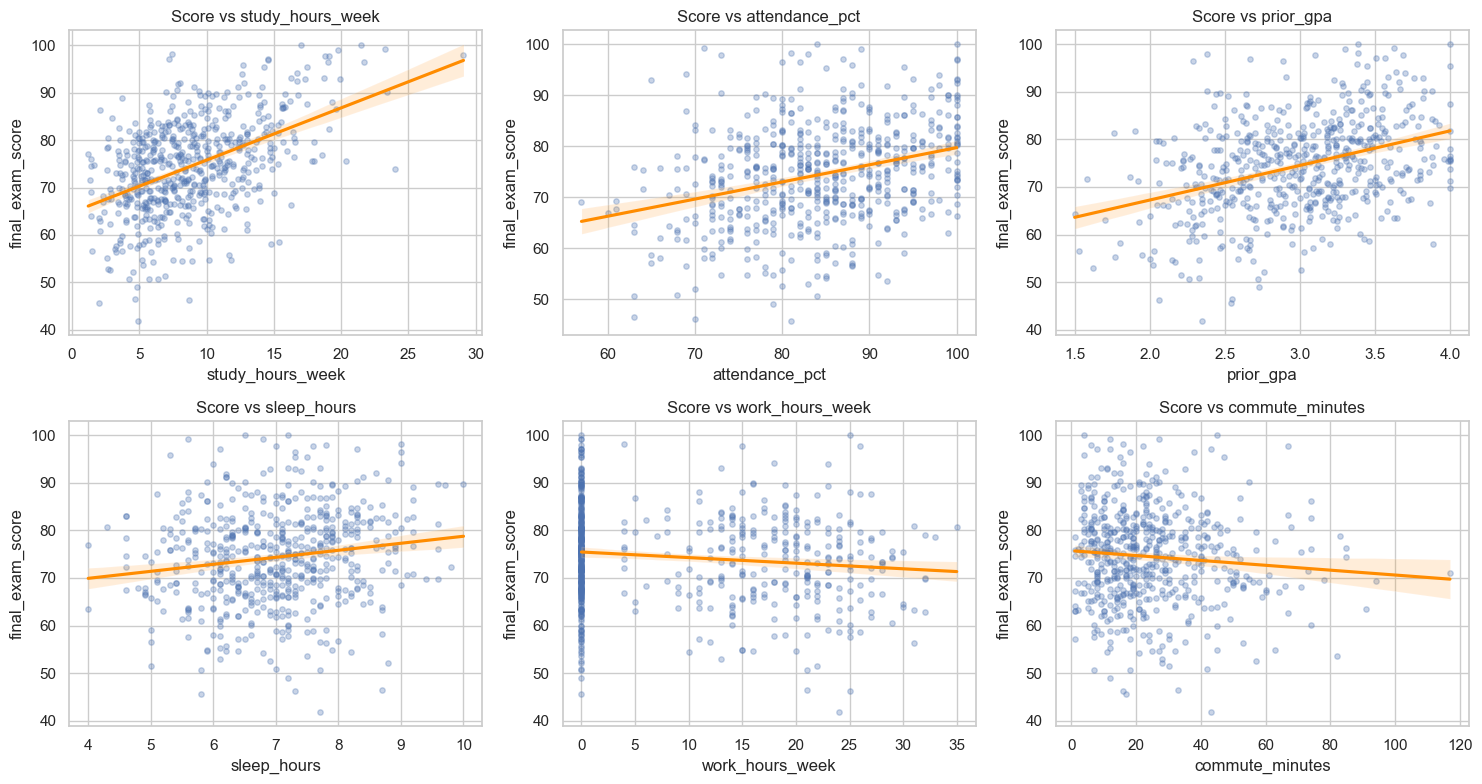

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.regplot(data=df, x=col, y="final_exam_score", ax=ax,
                scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "darkorange"})
    ax.set_title(f"Score vs {col}")
plt.tight_layout()
plt.show()

#### Cell: Scores by category

**What this cell does.** Compares the distribution of exam scores across majors, study-group membership and first-generation status.

**The code, line by line:**
- `order = df.groupby("major")["final_exam_score"].median().sort_values().index` sorts majors from lowest to highest median score, which makes the chart easier to read.
- `sns.boxplot(x=..., y=...)` draws one box per group.
- `tick_params(axis="x", rotation=30)` tilts long labels so they do not overlap.

**Why it matters.** Categorical predictors cannot go in a scatter plot. Boxplots show whether groups differ in their typical score and spread.

**How to read the output.** Study-group members score higher on average (**76.7 vs 73.2**). First-generation students score slightly lower (73.8 vs 74.7), a small difference. Majors overlap heavily; Data Science has the highest median and Health the lowest.

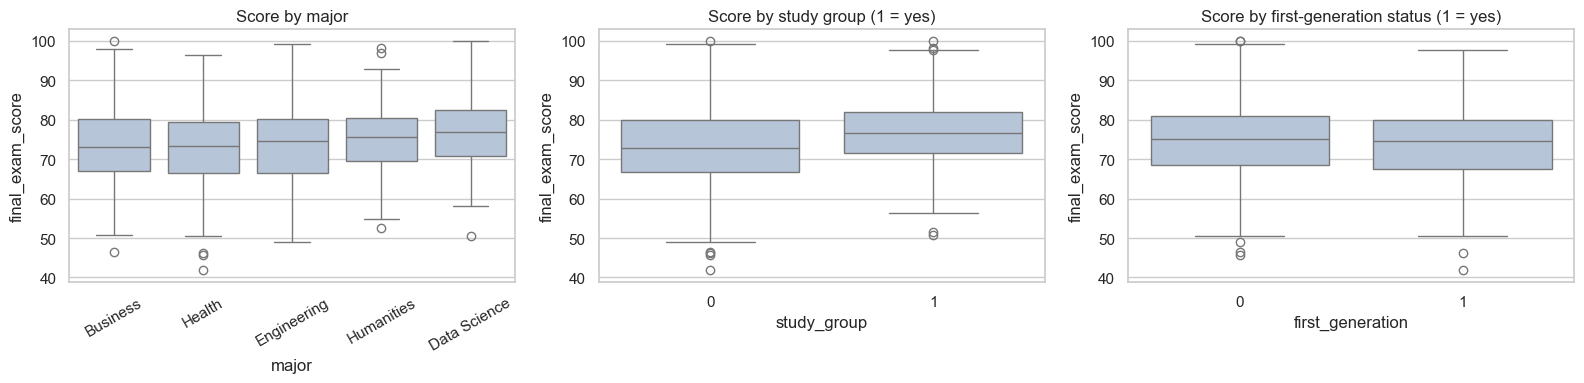

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = df.groupby("major")["final_exam_score"].median().sort_values().index
sns.boxplot(data=df, x="major", y="final_exam_score", order=order, ax=axes[0], color="lightsteelblue")
axes[0].set_title("Score by major"); axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="study_group", y="final_exam_score", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Score by study group (1 = yes)")
sns.boxplot(data=df, x="first_generation", y="final_exam_score", ax=axes[2], color="lightsteelblue")
axes[2].set_title("Score by first-generation status (1 = yes)")
plt.tight_layout()
plt.show()

#### Cell: Summary by major

**What this cell does.** Calculates the number of students and the mean, median and standard deviation of scores for each major.

**The code, line by line:**
- `df.groupby("major")` splits the data by major.
- `["final_exam_score"].agg(["count", "mean", "median", "std"])` computes several statistics at once for each group.

**Why it matters.** Puts exact numbers behind the boxplot, so you can report them.

**How to read the output.** Mean scores: Data Science 77.2, Humanities 75.4, Engineering 73.7, Business 73.5, Health 72.6. The range between majors (about 4.6 points) is smaller than the spread within each major (SD around 9–10). Remember these are raw differences; the regression will show whether they remain once study habits and GPA are accounted for.

In [14]:
df.groupby("major")["final_exam_score"].agg(["count", "mean", "median", "std"]).round(1)

,count,mean,median,std
major,,,,
Business,143,73.5,73.2,10.1
Data Science,122,77.2,76.8,9.1
Engineering,125,73.7,74.7,9.8
Health,116,72.6,73.2,10.7
Humanities,94,75.4,75.5,9.0


**EDA takeaways** (check these against your own output):
- Scores are roughly bell-shaped, centered in the mid-70s.
- Study hours, prior GPA and attendance show the clearest positive relationships with score; work hours and commute look slightly negative.
- Study-group members score higher on average. Differences between majors are small.
- No pair of predictors is so highly correlated that it would cause problems, except `works_part_time` and `work_hours_week`, which measure the same thing.

## 4. Prepare the data

Decisions:

1. **Drop `student_id`** — it is a label, not a predictor.
2. **Drop the other target.** `performance_level` is an outcome, not a cause; using it as a predictor would leak the answer.
3. **Drop `works_part_time`.** It carries the same information as `work_hours_week` (0 hours = no job), and including both makes the coefficients unstable.
4. **Split before filling gaps.** 80% of students train the model; 20% are held out to test it.
5. **Fill missing values with the median** of the training set. With under 5% missing per column, median imputation is simple and reasonable. Alternative: drop rows with missing values (`dropna()`), which would lose about 10% of the students.

#### Cell: Split the data and fill missing values

**What this cell does.** Splits students into a training set (80%) and a test set (20%), then fills missing numeric values using medians from the training set only.

**The code, line by line:**
- `train_test_split(df, test_size=0.2, random_state=42)` randomly assigns 20% of rows to `test`. `random_state=42` fixes the random shuffle so everyone gets the same split every time (any number works; 42 is a convention).
- `medians = train[numeric_cols].median()` computes each column's median **from the training set**.
- `.fillna(medians)` replaces each missing value with its column's median, in both sets.
- `.copy()` avoids pandas' "SettingWithCopy" warning by making independent tables.

**Why it matters.** - **Why split?** A model always looks better on the data it was fit to. The test set acts as "new students" and gives an honest measure of predictive accuracy.
- **Why the median?** It is not pulled by outliers (unlike the mean), and with under 5% missing it barely changes the distributions.
- **Why training medians only?** Using the test set to compute fill values would leak information from the "new students" into the model, a mistake called **data leakage**.

**How to read the output.** Training rows: **480**; test rows: **120**; missing values left: **0**. The medians used are printed (e.g., sleep 7.1 hours, commute 20 minutes).

In [15]:
numeric_cols = ["study_hours_week", "attendance_pct", "prior_gpa", "sleep_hours",
                "work_hours_week", "commute_minutes"]
binary_cols = ["works_part_time", "study_group", "first_generation"]

# Features and the two possible targets
features = ["major"] + numeric_cols + ["study_group", "first_generation"]

train, test = train_test_split(df, test_size=0.2, random_state=42)

# Fill missing numeric values with the TRAINING median (so the test set stays unseen)
medians = train[numeric_cols].median()
train = train.copy(); test = test.copy()
train[numeric_cols] = train[numeric_cols].fillna(medians)
test[numeric_cols] = test[numeric_cols].fillna(medians)

print("Training rows:", len(train), "| Test rows:", len(test))
print("Missing values left:", train[features].isna().sum().sum() + test[features].isna().sum().sum())
print("\nMedians used to fill gaps:\n", medians[["attendance_pct", "prior_gpa", "sleep_hours", "commute_minutes"]])

Training rows: 480 | Test rows: 120
Missing values left: 0

Medians used to fill gaps:
 attendance_pct     85.00
prior_gpa           3.02
sleep_hours         7.10
commute_minutes    20.00
dtype: float64


## 5. Fit the model

We use the statsmodels formula API. `C(major)` turns major into dummy variables, with **Business** as the reference group (the first alphabetically).

```
final_exam_score ~ study_hours_week + attendance_pct + prior_gpa + sleep_hours + work_hours_week + commute_minutes + study_group + first_generation + C(major)
```

#### Cell: Fit the multiple linear regression

**What this cell does.** Defines the model formula, fits an ordinary least squares (OLS) regression on the training data, and prints the full results table.

**The code, line by line:**
- The **formula** reads: *predict `final_exam_score` from* (`~`) the listed predictors, joined by `+`.
- `C(major)` tells statsmodels that `major` is **categorical**. It creates 4 dummy (0/1) variables, one per major except the **reference group**, Business (first alphabetically). Each major's coefficient is its difference from Business.
- `smf.ols(formula, data=train)` sets up the model; `.fit()` estimates the coefficients by **least squares** (minimizing the sum of squared prediction errors).
- `print(model.summary())` prints the standard regression table.

**Why it matters.** This is the core of the analysis: one equation that estimates the effect of each predictor **while holding all the others constant**.

**How to read the output.** Top block: **R-squared = 0.558** (the model explains about 56% of the variation in scores), **Adj. R-squared = 0.546** (adjusted for the number of predictors), and **Prob (F-statistic) ≈ 0** (the model as a whole is clearly better than predicting the average for everyone). **No. Observations = 480.**

Middle block (one row per predictor): `coef` is the estimated effect, `std err` its uncertainty, `t` = coef ÷ std err, `P>|t|` the p-value, and the last two columns the 95% confidence interval. For example, `study_hours_week` has coef **1.06**: each extra weekly study hour is associated with about one more exam point, holding everything else constant (p < 0.001).

Bottom block: diagnostic tests (Durbin-Watson, Jarque-Bera, condition number), covered in Section 7.

In [16]:
formula = ("final_exam_score ~ study_hours_week + attendance_pct + prior_gpa + sleep_hours"
           " + work_hours_week + commute_minutes + study_group + first_generation + C(major)")
model = smf.ols(formula, data=train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       final_exam_score   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.546
Method:                 Least Squares   F-statistic:                     49.05
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           6.70e-75
Time:                        07:39:40   Log-Likelihood:                -1588.4
No. Observations:                 480   AIC:                             3203.
Df Residuals:                     467   BIC:                             3257.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

### How to read the summary

- **R-squared:** share of the variation in scores the model explains.
- **coef:** expected change in the score for a one-unit increase in that predictor, **holding all others constant**. For a 0/1 variable, it is the difference between the two groups. For a major, it is the difference from Business.
- **P>|t|:** a small p-value (below 0.05) means the relationship is unlikely to be zero in the population.
- **[0.025 0.975]:** the 95% confidence interval for the coefficient. If it does not include 0, the effect is statistically significant at 5%.

#### Cell: Tidy coefficient table

**What this cell does.** Collects each coefficient, its 95% confidence interval and p-value into one table, flags the significant ones, and sorts by p-value.

**The code, line by line:**
- `model.params`: the coefficients. `model.conf_int()`: lower (`[0]`) and upper (`[1]`) bounds of the 95% confidence intervals. `model.pvalues`: the p-values.
- `.drop("Intercept")` removes the intercept, which is not a predictor.
- `np.where(coefs.p_value < 0.05, "yes", "no")` labels each predictor significant or not at the 5% level.

**Why it matters.** A cleaner version of the summary that is easy to put in a report or slide.

**How to read the output.** Significant (p < 0.05): sleep (+1.49 per hour), prior GPA (+7.68 per GPA point), attendance (+0.32 per percentage point), study hours (+1.06 per hour), study group (+3.33), work hours (−0.11 per hour) and Data Science major (+2.54 vs Business). Not significant: Health, Engineering and Humanities majors, first-generation status and commute; their confidence intervals include 0, so we cannot rule out no effect.

In [17]:
coefs = pd.DataFrame({"coef": model.params, "ci_low": model.conf_int()[0],
                      "ci_high": model.conf_int()[1], "p_value": model.pvalues}).drop("Intercept")
coefs["significant"] = np.where(coefs.p_value < 0.05, "yes", "no")
coefs.round(3).sort_values("p_value")

,coef,ci_low,ci_high,p_value,significant
study_hours_week,1.057,0.913,1.200,0.000,yes
attendance_pct,0.322,0.255,0.389,0.000,yes
prior_gpa,7.682,6.475,8.889,0.000,yes
sleep_hours,1.490,0.907,2.073,0.000,yes
work_hours_week,-0.115,-0.174,-0.055,0.000,yes
study_group,3.335,2.067,4.602,0.000,yes
C(major)[T.Data Science],2.543,0.721,4.365,0.006,yes
C(major)[T.Health],-1.703,-3.582,0.175,0.075,no
C(major)[T.Engineering],-1.448,-3.260,0.365,0.117,no
first_generation,-0.839,-2.115,0.436,0.197,no


## 6. Which variables matter most?

Raw coefficients cannot be compared directly because the predictors use different units (hours, %, GPA points). We refit the model with **standardized** numeric predictors: each coefficient then means *the change in score for a one-standard-deviation increase*, so they are on the same scale.

#### Cell: Standardized coefficients for importance

**What this cell does.** Rescales each numeric predictor to have mean 0 and standard deviation 1, refits the same model, and ranks predictors by the size of their effect.

**The code, line by line:**
- `(train[col] - train[col].mean()) / train[col].std()` converts a column to **z-scores**: 0 = average, +1 = one standard deviation above average.
- Refitting on `train_z` gives coefficients that mean *points gained for a 1-SD increase*.
- `.assign(abs_effect=lambda d: d.std_coef.abs())` adds the absolute size, so negative effects rank fairly; the table is sorted by it.

**Why it matters.** Raw coefficients cannot be compared across units: +7.7 per GPA point looks bigger than +1.06 per study hour, but a whole GPA point is a big change while one hour is small. Standardizing puts all numeric predictors on the same scale. The 0/1 variables and majors are left as they are (their coefficient is already a yes-vs-no difference).

**How to read the output.** Biggest effects: **study hours +4.5 points per SD** (one SD ≈ 4.2 hours), **prior GPA +3.9** (one SD ≈ 0.5 GPA points), **study group +3.3**, **attendance +2.9** (one SD ≈ 9 percentage points), Data Science +2.5, sleep +1.6, work hours −1.2. Commute (−0.3) and first-generation (−0.8) are small and not significant. R² and p-values are identical to the original model; only the scale of the coefficients changed.

In [18]:
# Standardize numeric predictors (mean 0, SD 1) so coefficients are comparable:
# each coefficient = change in the outcome for a 1-standard-deviation increase.
train_z = train.copy()
for col in numeric_cols:
    train_z[col] = (train[col] - train[col].mean()) / train[col].std()
model_z = smf.ols(formula, data=train_z).fit()

importance = (model_z.params.drop("Intercept")
              .rename("std_coef").to_frame()
              .assign(abs_effect=lambda d: d.std_coef.abs(), p_value=model_z.pvalues)
              .sort_values("abs_effect", ascending=False))
importance.round(3)

,std_coef,abs_effect,p_value
study_hours_week,4.475,4.475,0.000
prior_gpa,3.865,3.865,0.000
study_group,3.335,3.335,0.000
attendance_pct,2.926,2.926,0.000
C(major)[T.Data Science],2.543,2.543,0.006
C(major)[T.Health],-1.703,1.703,0.075
sleep_hours,1.553,1.553,0.000
C(major)[T.Engineering],-1.448,1.448,0.117
work_hours_week,-1.175,1.175,0.000
first_generation,-0.839,0.839,0.197


#### Cell: Importance chart

**What this cell does.** Draws the standardized coefficients as horizontal bars, colored orange if significant and gray if not.

**The code, line by line:**
- `colors = [...]` picks orange for p < 0.05 and light gray otherwise.
- `plt.barh(...)` draws horizontal bars; bars to the right of the black line at 0 raise scores, bars to the left lower them.

**Why it matters.** A chart communicates importance faster than a table, and the colors show at a glance which effects are reliable.

**How to read the output.** Study hours, prior GPA, study group and attendance have the longest orange bars: these are the most important predictors. Gray bars (Health, Engineering, Humanities, first-generation, commute) are not statistically distinguishable from zero.

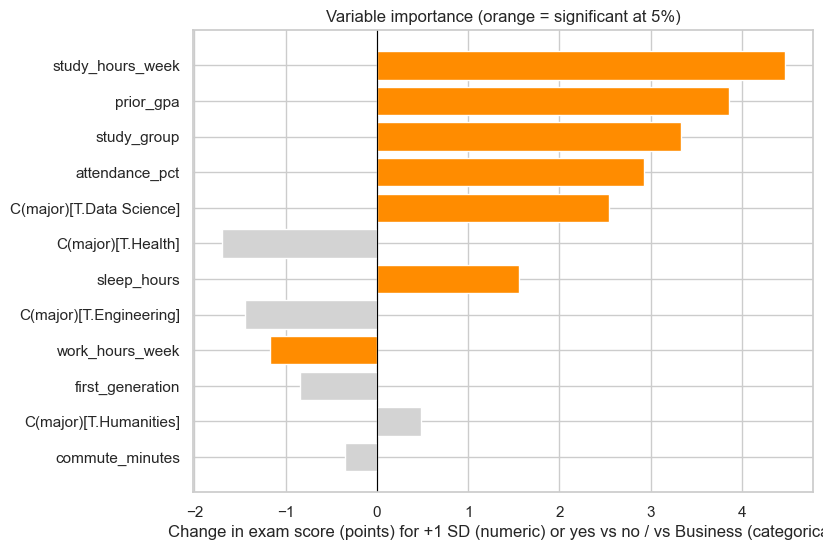

In [19]:
imp = importance.sort_values("abs_effect")
colors = ["darkorange" if p < 0.05 else "lightgray" for p in imp.p_value]
plt.figure(figsize=(8, 6))
plt.barh(imp.index, imp.std_coef, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in exam score (points) for +1 SD (numeric) or yes vs no / vs Business (categorical)")
plt.title("Variable importance (orange = significant at 5%)")
plt.show()

*Note:* 0/1 variables and majors are not standardized, so their bars show the full group difference. Compare them with the numeric bars with care.

## 7. Check the model assumptions

Linear regression gives trustworthy coefficients, p-values and confidence intervals only if a few conditions hold. We check each one with a plot and, where available, a formal test.

| # | Assumption | What it means | How we check |
| --- | --- | --- | --- |
| 1 | Linearity | Each predictor has a straight-line relationship with the score | Residuals vs each predictor; RESET test; squared terms |
| 2 | Independence | One student's error does not affect another's | Study design; Durbin-Watson |
| 3 | Equal variance (homoscedasticity) | Errors are about the same size for all predicted values | Residuals vs fitted; Breusch-Pagan test |
| 4 | Normal residuals | Errors follow a bell curve | Q-Q plot, histogram; Shapiro-Wilk and Jarque-Bera tests |
| 5 | No multicollinearity | Predictors are not near-copies of each other | Variance inflation factor (VIF) |
| 6 | No overly influential points | No single student drives the results | Studentized residuals, leverage, Cook's distance |

For each formal test, the **null hypothesis is that the assumption holds**. A p-value **above 0.05** means we find no evidence of a problem.

#### Cell: Import the diagnostic tools

**What this cell does.** Loads the tests used to check the assumptions and stores the residuals and fitted values for reuse.

**The code, line by line:**
- `het_breuschpagan`: test for unequal variance. `linear_reset`: test for missing curvature.
- `durbin_watson`: test for correlated errors. `jarque_bera` and `scipy.stats.shapiro`: tests for normality.
- `OLSInfluence`: outliers, leverage and Cook's distance.
- `model.resid` = actual − predicted score for each training student (the **residuals**). `model.fittedvalues` = the predicted scores.

**Why it matters.** Most assumption checks are about the residuals, the part of each score the model cannot explain.

**How to read the output.** Nothing is printed.

In [20]:
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import OLSInfluence
from scipy import stats

resid = model.resid
fitted = model.fittedvalues

### 7.1 Linearity

#### Cell: Linearity: residual plots and tests

**What this cell does.** Plots the residuals against each numeric predictor with a smoothed trend line, runs the RESET test, and tests a squared term for each predictor.

**The code, line by line:**
- `sns.regplot(..., lowess=True, scatter=False)` draws a **LOWESS** line, a flexible smoother that follows the data wherever it goes. If the true relationship were curved, this line would bend.
- `linear_reset(model, power=2, use_f=True)` (Ramsey RESET) adds the squared predicted values to the model and tests whether they help. If they do, some curvature is missing.
- The loop refits the model with `I(col**2)` (a squared version of one predictor, `I()` means "compute this") and records its p-value.

**Why it matters.** If a relationship is curved but modeled as a straight line, the coefficient is a misleading average and predictions are biased at the extremes.

**How to read the output.** Look for flat smoothed lines near 0 and p-values above 0.05. The interpretation paragraph below the output gives the verdict.

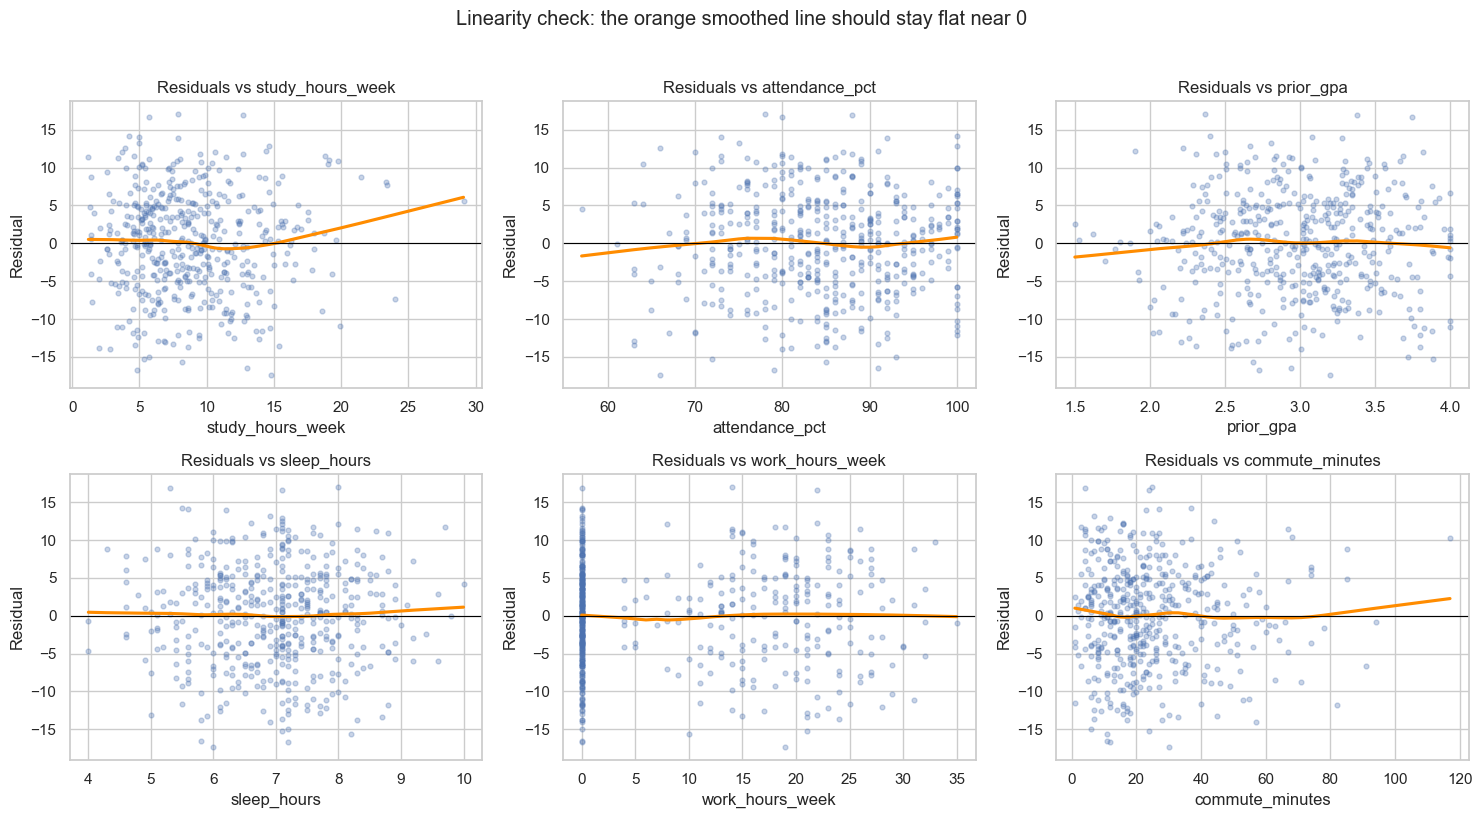

Ramsey RESET test: F = 0.79, p = 0.374


,predictor,p-value of squared term
0,study_hours_week,0.070
1,attendance_pct,0.860
2,prior_gpa,0.224
3,sleep_hours,0.425
4,work_hours_week,0.787
5,commute_minutes,0.301


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    ax.scatter(train[col], resid, alpha=0.3, s=12)
    sns.regplot(x=train[col], y=resid, lowess=True, scatter=False, ax=ax, line_kws={"color": "darkorange"})
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Residuals vs {col}"); ax.set_ylabel("Residual")
plt.suptitle("Linearity check: the orange smoothed line should stay flat near 0", y=1.02)
plt.tight_layout()
plt.show()

reset = linear_reset(model, power=2, use_f=True)
print(f"Ramsey RESET test: F = {reset.fvalue:.2f}, p = {reset.pvalue:.3f}")

rows = []
for col in numeric_cols:
    m_sq = smf.ols(formula + f" + I({col}**2)", data=train).fit()
    rows.append({"predictor": col, "p-value of squared term": round(m_sq.pvalues[f"I({col} ** 2)"], 3)})
pd.DataFrame(rows)

**Interpretation.** For most predictors the smoothed lines in the residual plots stay close to zero across their whole range. The study-hours line bends upward at the far right, but that bend is driven by a handful of students who study more than 20 hours a week, where there is little data. The Ramsey RESET test, which checks whether the model is missing curved relationships, is not significant (F = 0.79, p = 0.37). Adding a squared term for each predictor one at a time also does not improve the model: all p-values are above 0.05, the smallest being study hours (p = 0.07). **The linearity assumption is reasonable.** Study hours is the one to keep an eye on; with more data, a slight curve (diminishing returns to studying) might become significant.

### 7.2 Independence

#### Cell: Independence: Durbin-Watson

**What this cell does.** Computes the Durbin-Watson statistic, which detects correlation between neighboring residuals.

**The code, line by line:**
- `durbin_watson(resid)` returns a number from 0 to 4. **About 2** means no correlation; below 1.5 suggests positive correlation, above 2.5 negative correlation.

**Why it matters.** Independence is mostly guaranteed by the study design (each row a different student). Durbin-Watson is most useful when rows have a natural order, such as time series; here it is a quick sanity check.

**How to read the output.** See the paragraph below the output.

In [22]:
dw = durbin_watson(resid)
print(f"Durbin-Watson statistic: {dw:.2f}   (about 2 = no correlation between neighboring errors; below 1.5 or above 2.5 is a concern)")

Durbin-Watson statistic: 1.97   (about 2 = no correlation between neighboring errors; below 1.5 or above 2.5 is a concern)


**Interpretation.** Independence is mainly a question of how the data was collected: each row is a different student, measured once, so one student's result should not influence another's. The Durbin-Watson statistic of 1.97 is very close to the ideal value of 2, confirming that errors are not correlated across rows. **The independence assumption is met.** It would be violated if, for example, the same student appeared several times, or if students in the same class section shared unmeasured influences such as the same instructor.

### 7.3 Equal variance (homoscedasticity)

#### Cell: Equal variance: residual plots and Breusch-Pagan

**What this cell does.** Plots residuals against predicted scores and a scale-location plot, then runs the Breusch-Pagan test.

**The code, line by line:**
- **Residuals vs fitted** (left): each dot is a student; the x-axis is their predicted score, the y-axis how far off the prediction was.
- **Scale-location** (right): the y-axis is √|standardized residual|, which focuses on the *size* of errors. A rising line would mean errors grow with the predicted score.
- `het_breuschpagan(resid, model.model.exog)` regresses the squared residuals on the predictors; a significant result means the error size depends on the predictors. It returns four numbers; we use the LM statistic and its p-value.

**Why it matters.** Unequal variance (heteroscedasticity) does not bias the coefficients, but it makes standard errors and p-values wrong. A funnel shape is the classic warning sign.

**How to read the output.** Look for an even horizontal band, a flat scale-location line, and a Breusch-Pagan p-value above 0.05.

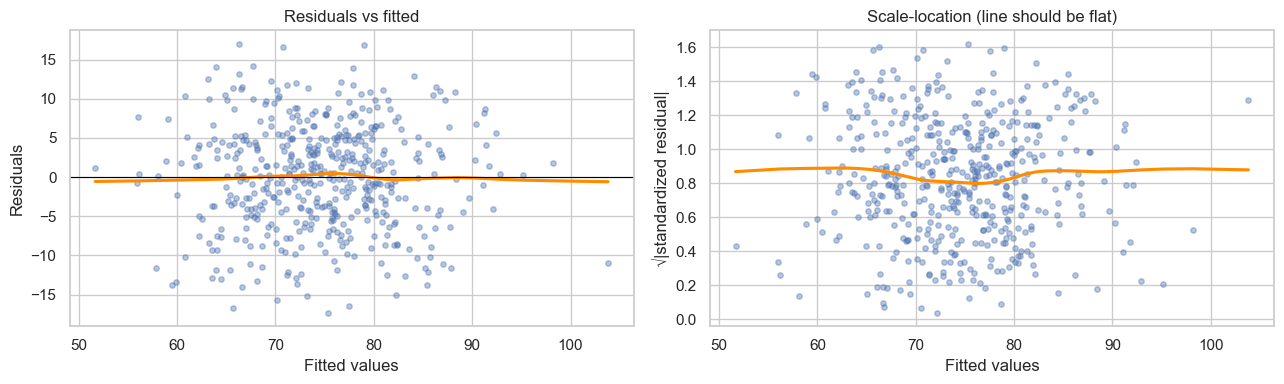

Breusch-Pagan test: LM = 12.63, p = 0.397


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(fitted, resid, alpha=0.4, s=15)
sns.regplot(x=fitted, y=resid, lowess=True, scatter=False, ax=axes[0], line_kws={"color": "darkorange"})
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Fitted values"); axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs fitted")
axes[1].scatter(fitted, np.sqrt(np.abs(model.get_influence().resid_studentized_internal)), alpha=0.4, s=15)
sns.regplot(x=fitted, y=np.sqrt(np.abs(model.get_influence().resid_studentized_internal)), lowess=True,
            scatter=False, ax=axes[1], line_kws={"color": "darkorange"})
axes[1].set_xlabel("Fitted values"); axes[1].set_ylabel("√|standardized residual|")
axes[1].set_title("Scale-location (line should be flat)")
plt.tight_layout()
plt.show()

bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan test: LM = {bp_lm:.2f}, p = {bp_lm_p:.3f}")

**Interpretation.** In the residuals-vs-fitted plot the points form an even horizontal band around zero; they do not fan out (a funnel shape) as predicted scores rise. The scale-location line is nearly flat, meaning the typical size of the errors is similar for low and high predicted scores. The Breusch-Pagan test agrees (p = 0.40), so there is no evidence of unequal variance. **The equal-variance assumption is met**, which means the standard errors and p-values in the summary can be trusted without corrections such as robust standard errors.

### 7.4 Normality of residuals

#### Cell: Normality of residuals

**What this cell does.** Draws a Q-Q plot and a histogram of the residuals and runs two normality tests.

**The code, line by line:**
- `sm.qqplot(resid, line="45", fit=True)` plots the residuals' quantiles against those of a perfect normal distribution. Points on the line = normal.
- `stats.shapiro(resid)`: the Shapiro-Wilk test. `jarque_bera(resid)`: a test based on skewness and kurtosis.
- `stats.skew` (0 = symmetric) and `stats.kurtosis` (excess kurtosis, 0 = normal tails).

**Why it matters.** Normal residuals make the t-tests and confidence intervals exact. With large samples (here 480), the tests stay approximately valid even with moderate non-normality.

**How to read the output.** Look for points hugging the line, a bell-shaped histogram, and p-values above 0.05. Curved ends of the Q-Q plot would indicate heavy or light tails.

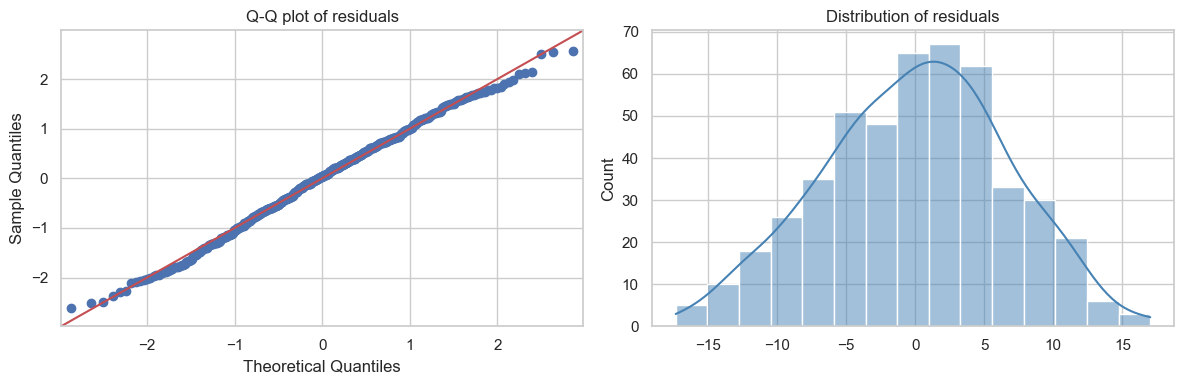

Shapiro-Wilk: W = 0.995, p = 0.134
Jarque-Bera:  JB = 4.02, p = 0.134
Skewness = -0.12, excess kurtosis = -0.38


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.qqplot(resid, line="45", fit=True, ax=axes[0])
axes[0].set_title("Q-Q plot of residuals")
sns.histplot(resid, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of residuals")
plt.tight_layout()
plt.show()

sw = stats.shapiro(resid)
jb_stat, jb_p = jarque_bera(resid)[:2]
print(f"Shapiro-Wilk: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")
print(f"Jarque-Bera:  JB = {jb_stat:.2f}, p = {jb_p:.3f}")
print(f"Skewness = {stats.skew(resid):.2f}, excess kurtosis = {stats.kurtosis(resid):.2f}")

**Interpretation.** The points in the Q-Q plot lie close to the diagonal line, and the histogram of residuals is roughly bell-shaped. Both formal tests are not significant (Shapiro-Wilk p = 0.13, Jarque-Bera p = 0.13), and skewness (−0.12) and excess kurtosis (−0.38) are close to zero. **The residuals are approximately normal.** With 480 students this assumption matters less anyway: thanks to the central limit theorem, coefficient tests stay reliable even when residuals are somewhat non-normal.

### 7.5 Multicollinearity

#### Cell: Multicollinearity: VIF

**What this cell does.** Calculates the variance inflation factor for each predictor.

**The code, line by line:**
- `model.model.exog` is the matrix of predictor values the model used (including the dummy variables and a column of 1s for the intercept); `model.model.exog_names` are their names.
- `variance_inflation_factor(X, i)` regresses predictor *i* on all the others. VIF = 1 ÷ (1 − R²) of that regression. VIF = 1 means unrelated to the others; VIF = 5 means the variance of its coefficient is 5 times larger than it would be without overlap.

**Why it matters.** When predictors overlap heavily, the model cannot tell their effects apart: coefficients become unstable, can flip sign, and get large standard errors.

**How to read the output.** Rule of thumb: below 5 is fine, 5–10 is a concern, above 10 is serious.

In [25]:
vif = pd.DataFrame({"variable": model.model.exog_names,
                    "VIF": [variance_inflation_factor(model.model.exog, i)
                            for i in range(model.model.exog.shape[1])]})
vif = vif[vif.variable != "Intercept"].round(2)
print("Rule of thumb: VIF above 5 is a concern, above 10 is serious")
vif

Rule of thumb: VIF above 5 is a concern, above 10 is serious


,variable,VIF
1,C(major)[T.Data Science],1.49
2,C(major)[T.Engineering],1.50
3,C(major)[T.Health],1.46
4,C(major)[T.Humanities],1.42
5,study_hours_week,1.02
6,attendance_pct,1.02
7,prior_gpa,1.02
8,sleep_hours,1.02
9,work_hours_week,1.02
10,commute_minutes,1.05


**Interpretation.** Every VIF is between 1.0 and 1.5, far below the warning level of 5. The predictors carry largely separate information, so each coefficient can be estimated precisely and interpreted as the effect of that variable holding the others constant. **There is no multicollinearity problem.** This is partly because we dropped `works_part_time` in Section 4: it duplicates `work_hours_week`, and keeping both would have inflated their VIFs. The summary's note about a large condition number comes from predictors measured on very different scales (attendance in the 80s vs 0/1 variables), not from collinearity, as the VIFs show.

### 7.6 Outliers and influential points

#### Cell: Outliers and influential points

**What this cell does.** Measures how unusual and how influential each training student is, plots Cook's distance, and refits the model without the flagged students to see whether the results change.

**The code, line by line:**
- **Studentized residual**: a residual divided by its standard error. Beyond ±3 suggests an outlier (a score the model predicts very poorly).
- **Leverage** (`hat_matrix_diag`): how unusual a student's *predictor* values are. Above 2p/n is considered high (p = number of coefficients, n = sample size).
- **Cook's distance**: combines both into how much all the coefficients would change if that student were removed. Above 4/n is a cautious flag; above 1 is a serious problem.
- `model_trim` refits on students with Cook's distance ≤ 4/n; the final table compares the coefficients side by side.

**Why it matters.** A few unusual cases can pull a regression line toward themselves. If removing them changes the conclusions, the results are fragile.

**How to read the output.** Look at the counts, the height of the tallest spike, and whether coefficients in the two columns are close.

Students with |studentized residual| > 3 (outliers): 0
Students with high leverage (> 2p/n = 0.054):     6
Students with Cook's distance > 4/n = 0.0083:       27
Students with Cook's distance > 1 (serious):        0   (largest = 0.018)


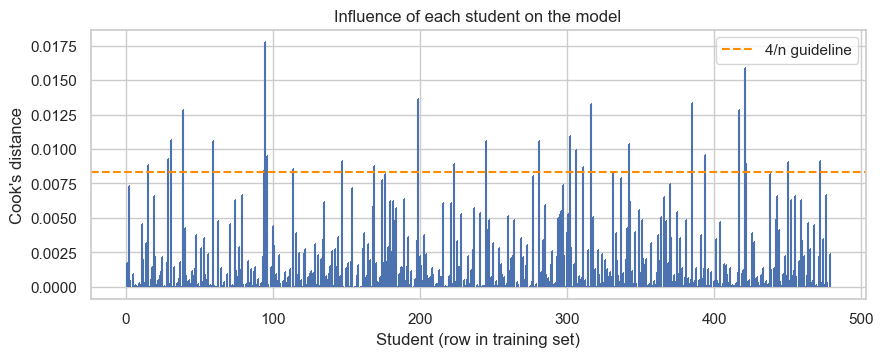

,all students,without 27 flagged
Intercept,5.131,5.254
C(major)[T.Data Science],2.543,2.873
C(major)[T.Engineering],-1.448,-1.426
C(major)[T.Health],-1.703,-1.709
C(major)[T.Humanities],0.480,0.422
study_hours_week,1.057,1.042
attendance_pct,0.322,0.320
prior_gpa,7.682,7.846
sleep_hours,1.490,1.509
work_hours_week,-0.115,-0.115


In [26]:
infl = OLSInfluence(model)
cooks = infl.cooks_distance[0]
stud = infl.resid_studentized_external
lev = infl.hat_matrix_diag
n, p = len(train), int(model.df_model) + 1

print(f"Students with |studentized residual| > 3 (outliers): {(np.abs(stud) > 3).sum()}")
print(f"Students with high leverage (> 2p/n = {2*p/n:.3f}):     {(lev > 2*p/n).sum()}")
print(f"Students with Cook's distance > 4/n = {4/n:.4f}:       {(cooks > 4/n).sum()}")
print(f"Students with Cook's distance > 1 (serious):        {(cooks > 1).sum()}   (largest = {cooks.max():.3f})")

plt.figure(figsize=(10, 3.5))
plt.stem(range(n), cooks, markerfmt=",", basefmt=" ")
plt.axhline(4/n, color="darkorange", linestyle="--", label="4/n guideline")
plt.xlabel("Student (row in training set)"); plt.ylabel("Cook's distance")
plt.title("Influence of each student on the model"); plt.legend()
plt.show()

# Does removing the flagged students change the conclusions?
model_trim = smf.ols(formula, data=train[cooks <= 4/n]).fit()
pd.DataFrame({"all students": model.params, f"without {(cooks > 4/n).sum()} flagged": model_trim.params}).round(3)

**Interpretation.** No student has a studentized residual beyond ±3, so there are no extreme outliers in the scores. Six students have somewhat high leverage (unusual combinations of predictor values), and 27 exceed the conservative Cook's distance guideline of 4/n, but the largest Cook's distance is only 0.018, far below the level of 1 that signals a seriously influential point. Refitting without those 27 students leaves every coefficient nearly unchanged (for example, study hours 1.06 vs 1.04 and prior GPA 7.68 vs 7.85), and no conclusion about significance changes. **No single student or small group drives the results.**

### 7.7 Summary of the assumption checks

#### Cell: Summary table of assumption checks

**What this cell does.** Gathers the key statistic and verdict for every assumption into one table.

**The code, line by line:**
- Each row is built from results computed above (`reset.pvalue`, `dw`, `bp_lm_p`, `sw.pvalue`, `vif.VIF.max()`, `cooks.max()`), so the table updates automatically when you rerun with new data. The verdict column is typed by hand, so check it.

**Why it matters.** A one-glance summary for a report or presentation.

In [27]:
pd.DataFrame([
    ["Linearity", f"RESET p = {reset.pvalue:.2f}", "Met"],
    ["Independence", f"Durbin-Watson = {dw:.2f}", "Met"],
    ["Equal variance", f"Breusch-Pagan p = {bp_lm_p:.2f}", "Met"],
    ["Normal residuals", f"Shapiro-Wilk p = {sw.pvalue:.2f}", "Met"],
    ["No multicollinearity", f"max VIF = {vif.VIF.max():.2f}", "Met"],
    ["No influential points", f"max Cook's D = {cooks.max():.3f}", "Met"],
], columns=["Assumption", "Evidence", "Verdict"])

,Assumption,Evidence,Verdict
0,Linearity,RESET p = 0.37,Met
1,Independence,Durbin-Watson = 1.97,Met
2,Equal variance,Breusch-Pagan p = 0.40,Met
3,Normal residuals,Shapiro-Wilk p = 0.13,Met
4,No multicollinearity,max VIF = 1.50,Met
5,No influential points,max Cook's D = 0.018,Met


**Overall.** All six assumptions are reasonably satisfied: relationships are linear, errors are independent, equally spread and approximately normal, predictors are not redundant, and no student unduly influences the fit. We can therefore trust the coefficient estimates, standard errors, confidence intervals and p-values reported in Section 5, and the importance ranking in Section 6. The checks do not, however, make the results causal; they only confirm that the model describes the associations in this data correctly.

*Using this as a template:* if a check fails with your own data, common fixes are a log or square-root transformation of the outcome (unequal variance or skewed residuals), adding a squared term (curvature), robust standard errors with `.fit(cov_type="HC3")` (unequal variance), or dropping one of two highly correlated predictors (high VIF).

## 8. Performance: how well does the model predict new students?

#### Cell: Predict the test set

**What this cell does.** Uses the fitted model to predict exam scores for the 120 held-out students and measures how close the predictions are.

**The code, line by line:**
- `model.predict(test)` applies the regression equation to the test students' predictor values.
- **R²** on the test set = 1 − (sum of squared errors ÷ total sum of squares): the share of score variation explained among new students.
- **RMSE** (root mean squared error): the typical prediction error, in exam points, penalizing big misses more.
- **MAE** (mean absolute error): the average size of the error, in exam points.
- The scatter plot compares actual and predicted scores; the orange diagonal is perfect prediction.

**Why it matters.** The training R² measures fit; the test metrics measure how well the model **generalizes**. A large gap between them would signal overfitting.

**How to read the output.** Training R² 0.558 vs **test R² 0.468**: a modest drop, so the model generalizes reasonably. **RMSE 7.05** and **MAE 5.94** points: a typical prediction is off by about 6 points on a 100-point exam. Points scatter around the diagonal without systematic bias; the model tends to pull extreme scores toward the middle, which is normal for regression.

Training R²: 0.558
Test R²:     0.468
Test RMSE:   7.05 points
Test MAE:    5.94 points


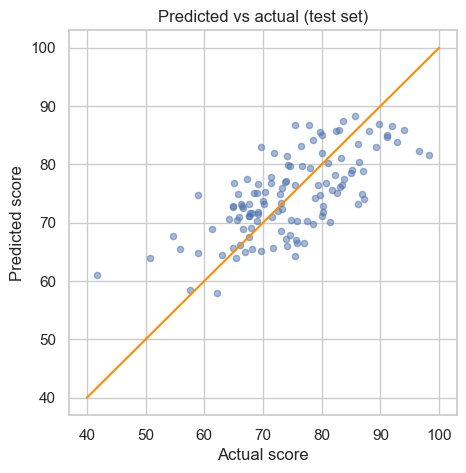

In [28]:
pred = model.predict(test)
resid = test["final_exam_score"] - pred
r2_test = 1 - (resid**2).sum() / ((test["final_exam_score"] - test["final_exam_score"].mean())**2).sum()
rmse = np.sqrt((resid**2).mean())
mae = resid.abs().mean()
print(f"Training R²: {model.rsquared:.3f}")
print(f"Test R²:     {r2_test:.3f}")
print(f"Test RMSE:   {rmse:.2f} points")
print(f"Test MAE:    {mae:.2f} points")

plt.figure(figsize=(5, 5))
plt.scatter(test["final_exam_score"], pred, alpha=0.5, s=20)
lims = [40, 100]
plt.plot(lims, lims, color="darkorange")
plt.xlabel("Actual score"); plt.ylabel("Predicted score")
plt.title("Predicted vs actual (test set)")
plt.show()

### 8.1 Performance metrics summary

A model's numbers mean little on their own. We compare it with a **baseline** that ignores every predictor and simply predicts the training-set average score for every student. A useful model must clearly beat it.

#### Cell: Performance metrics vs a baseline

**What this cell does.** Computes four error measures for the model on the test set, computes the same measures for a naive baseline, and shows them side by side.

**The code, line by line:**
- `np.full(len(test), train["final_exam_score"].mean())` creates the baseline prediction: the training average for every test student.
- `reg_metrics(y, yhat)` is a small helper function returning:
    - **R²** = 1 − (sum of squared errors ÷ total variation): share of variation explained.
    - **RMSE** = √(mean squared error): typical error, in points, punishing large misses.
    - **MAE** = mean absolute error, in points: the average miss.
    - **MAPE** = mean absolute percentage error: the average miss as a % of the actual score.
- `model.rsquared_adj` adds the training adjusted R² for comparison.

**Why it matters.** "RMSE = 7" is only meaningful next to something. The baseline shows how much the predictors actually add.

**How to read the output.** Compare the two columns row by row: higher R², and lower RMSE, MAE and MAPE are better. See the paragraph below.

In [29]:
baseline_pred = np.full(len(test), train["final_exam_score"].mean())
y_true = test["final_exam_score"]

def reg_metrics(y, yhat):
    err = y - yhat
    return {"R²": 1 - (err**2).sum() / ((y - y.mean())**2).sum(),
            "RMSE (points)": np.sqrt((err**2).mean()),
            "MAE (points)": err.abs().mean(),
            "MAPE (%)": (err.abs() / y).mean() * 100}

perf = pd.DataFrame({"Model (test set)": reg_metrics(y_true, pred),
                     "Baseline: predict the average": reg_metrics(y_true, baseline_pred)}).round(3)
perf.loc["Adjusted R² (training)"] = [round(model.rsquared_adj, 3), np.nan]
perf

,Model (test set),Baseline: predict the average
R²,0.468,-0.000
RMSE (points),7.048,9.668
MAE (points),5.943,7.677
MAPE (%),8.197,10.690
Adjusted R² (training),0.546,NaN


**Interpretation.** On the 120 test students the model explains about 47% of the variation in scores (R² = 0.47), while the baseline explains none (R² ≈ 0), as expected for a prediction that ignores every student's characteristics. The model's typical error is about **6 points** (MAE = 5.9, RMSE = 7.1), compared with about **7.7 points** (MAE) and **9.7 points** (RMSE) for the baseline. That is roughly a 25% reduction in error. On average the predictions are off by about **8% of the actual score** (MAPE), vs 10.7% for the baseline. RMSE is larger than MAE because it penalizes big misses more heavily; the gap between them is small here, meaning the model rarely makes very large errors. The training adjusted R² (0.55) is close to the test R², so the model is not overfitting much.

## 9. Fairness metrics

A model can be accurate overall and still work worse for some groups of students. If a model like this one were used to decide who gets tutoring or an early-warning email, those differences would matter. **Fairness metrics** compare the model's behavior across groups.

**Groups we compare:**
- `first_generation`: first-generation college students vs others. This is the main background characteristic in the data.
- `works_part_time`: students with a job vs without, a rough proxy for financial pressure.

**Why cross-validation?** The test set has only about 26–33 first-generation students, so group-level rates from it would be very noisy. Instead we use **5-fold cross-validation**: the data is split into 5 parts; each part is predicted by a model trained on the other 4. Every one of the 600 students then gets a prediction from a model that never saw them, giving larger and more reliable groups.

There is no single definition of fairness, and some definitions conflict with each other. We report a couple of common ones and discuss what they mean.

**Fairness metrics for a regression model:**

| Metric | Question it answers | Fair if |
| --- | --- | --- |
| **Error parity** (MAE by group) | Is the model equally accurate for each group? | MAEs are similar |
| **Prediction bias** (mean residual by group) | Does the model systematically over- or under-predict one group? | Mean residual near 0 for every group |
| **Equal opportunity for an at-risk flag** | If we flag students predicted below 68 as "at risk," do truly at-risk students in each group get flagged at the same rate? | Flag rates among truly at-risk students are similar |

#### Cell: Cross-validated predictions for fairness

**What this cell does.** Gives every student in the dataset a prediction from a model that was trained without them, using 5-fold cross-validation, and marks who is truly at risk and who would be flagged.

**The code, line by line:**
- `KFold(n_splits=5, shuffle=True, random_state=42)` splits the 600 students into 5 random groups of 120.
- In each round, the model is fit on 4 groups (`tr`) and predicts the 5th (`te`). Missing values are filled with medians **from that round's training data**, as before, to avoid leakage.
- `cv.loc[cv.index[test_idx], "cv_pred"] = ...` stores each student's prediction in the right row.
- `residual` = actual − predicted (positive means the model under-predicted that student).
- `AT_RISK = 68` defines an illustrative cutoff; `truly_at_risk` and `flagged` mark students below it in reality and in the prediction.

**Why it matters.** Fairness compares small subgroups. Using all 600 students instead of 120 test students makes the group comparisons much more stable.

**How to read the output.** The overall cross-validated MAE (about 5.5 points) should be close to the test-set MAE, which confirms the cross-validated predictions behave like the test set.

In [30]:
from sklearn.model_selection import KFold

# Out-of-fold predictions: each student is predicted by a model trained without them
cv = df.copy()
cv["cv_pred"] = np.nan
for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(df):
    tr, te = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
    fold_medians = tr[numeric_cols].median()
    tr[numeric_cols] = tr[numeric_cols].fillna(fold_medians)
    te[numeric_cols] = te[numeric_cols].fillna(fold_medians)
    cv.loc[cv.index[test_idx], "cv_pred"] = smf.ols(formula, data=tr).fit().predict(te).values

cv["residual"] = cv["final_exam_score"] - cv["cv_pred"]      # positive = model under-predicts
AT_RISK = 68
cv["truly_at_risk"] = cv["final_exam_score"] < AT_RISK
cv["flagged"] = cv["cv_pred"] < AT_RISK
print(f"Cross-validated MAE, all students: {cv.residual.abs().mean():.2f} points")

Cross-validated MAE, all students: 5.55 points


#### Cell: Fairness metrics by group

**What this cell does.** Calculates error parity, prediction bias and equal opportunity for each group, plus the gap between groups, for first-generation status and part-time work.

**The code, line by line:**
- For each group, the function computes: the number of students, **MAE** (error parity), the **mean residual** (prediction bias: positive = under-predicted, negative = over-predicted), how many are truly at risk, and the **% of truly at-risk students flagged** (equal opportunity, also called the true positive rate).
- The last row is the **gap**: second group minus first group.
- `display(...)` shows a formatted table even when it is not the last line of the cell.

**Why it matters.** These numbers show whether the model's mistakes fall evenly or concentrate on one group.

**How to read the output.** Look at the gap row. Gaps near 0 mean the groups are treated similarly. For MAE and the flag rate, also judge size: a 0.3-point MAE gap is negligible; a 10-point gap in the share flagged is worth discussing.

In [31]:
def regression_fairness(data, group_col, labels):
    rows = []
    for value, label in labels.items():
        g = data[data[group_col] == value]
        at_risk = g[g.truly_at_risk]
        rows.append({"group": label, "students": len(g),
                     "MAE (points)": g.residual.abs().mean(),
                     "mean residual (points)": g.residual.mean(),
                     "truly at risk": len(at_risk),
                     "at-risk students flagged (%)": at_risk.flagged.mean() * 100})
    table = pd.DataFrame(rows).set_index("group")
    gaps = table.iloc[1] - table.iloc[0]
    table.loc["gap (second − first)"] = gaps
    table.loc["gap (second − first)", ["students", "truly at risk"]] = np.nan
    return table.round(2)

fair_fg = regression_fairness(cv, "first_generation", {0: "Not first-gen", 1: "First-gen"})
fair_work = regression_fairness(cv, "works_part_time", {0: "No job", 1: "Works part-time"})
print("By first-generation status"); display(fair_fg)
print("By part-time work"); display(fair_work)

By first-generation status


,students,MAE (points),mean residual (points),truly at risk,at-risk students flagged (%)
group,,,,,
Not first-gen,408.0,5.64,0.03,100.0,51.00
First-gen,192.0,5.34,-0.02,52.0,61.54
gap (second − first),NaN,-0.30,-0.04,NaN,10.54


By part-time work


,students,MAE (points),mean residual (points),truly at risk,at-risk students flagged (%)
group,,,,,
No job,319.0,5.46,0.03,72.0,55.56
Works part-time,281.0,5.64,-0.01,80.0,53.75
gap (second − first),NaN,0.18,-0.04,NaN,-1.81


#### Cell: Fairness chart

**What this cell does.** Plots the three fairness metrics side by side for the four groups.

**The code, line by line:**
- Each panel is one metric; purple bars are the comparison groups (not first-gen, no job), orange bars the groups of interest (first-gen, works part-time).
- The mean-residual panel has a line at 0 and a fixed scale of ±2 points, so small differences are not visually exaggerated.

**Why it matters.** Equal-height bars within each pair mean the model treats those groups similarly.

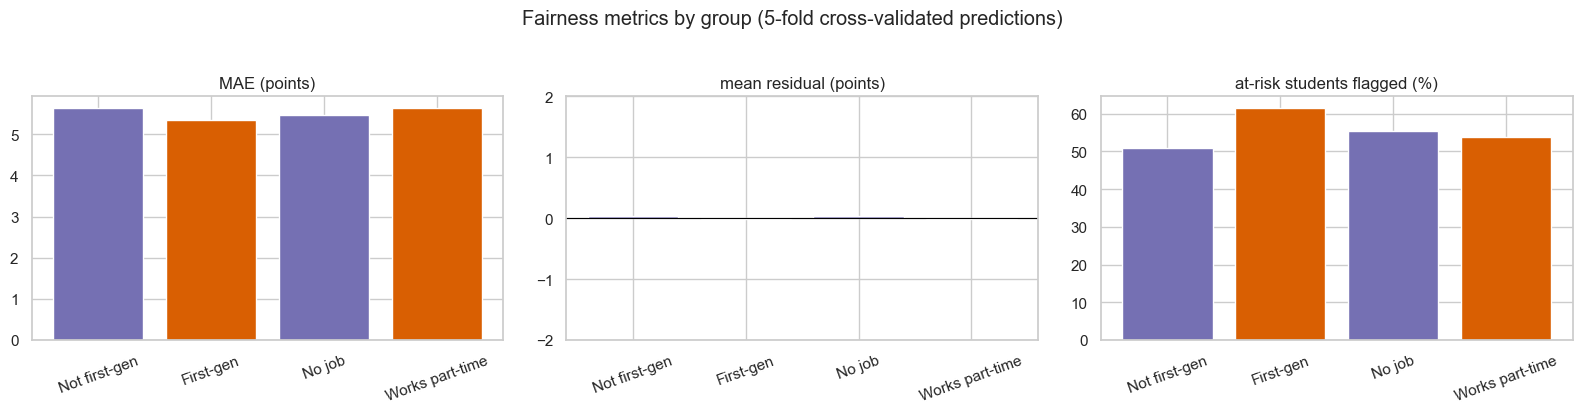

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE (points)", "mean residual (points)", "at-risk students flagged (%)"]):
    vals = pd.concat([fair_fg[metric].iloc[:2], fair_work[metric].iloc[:2]])
    ax.bar(vals.index, vals.values, color=["#7570b3", "#d95f02", "#7570b3", "#d95f02"])
    ax.set_title(metric); ax.tick_params(axis="x", rotation=20)
    if metric.startswith("mean"): ax.axhline(0, color="black", linewidth=0.8); ax.set_ylim(-2, 2)
plt.suptitle("Fairness metrics by group (5-fold cross-validated predictions)", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation.** By these measures the linear model treats the groups fairly.

- **Error parity:** the typical error is about the same for every group: 5.6 points for non-first-generation students and 5.3 for first-generation students, and 5.5 vs 5.6 points for students without and with a job. Differences of 0.2–0.3 points are negligible on a 100-point exam.
- **Prediction bias:** the mean residual is within ±0.03 points of zero for all four groups, so the model does not systematically over- or under-predict anyone. Part of the reason is that `first_generation` and `work_hours_week` are in the model, which lets it adjust for each group's average.
- **Equal opportunity:** if students predicted below 68 were flagged as at risk, the model would catch about half of the truly at-risk students in each group. It would catch somewhat more of the first-generation ones (62% vs 51%, a 10-point gap) and about the same share of working and non-working students (54% vs 56%). The first-generation gap favors the group we might most want to support, and it rests on only 52 at-risk first-generation students, so it could partly be chance.

**The bigger fairness issue is not between groups but overall:** about half of all at-risk students would be missed in every group. If this model were used for early alerts, a higher threshold (for example, flagging below 72) would catch more students at the cost of more false alarms.

**A caution about including group variables:** we kept `first_generation` in the model because it is part of the research question. Whether a model used for real decisions *should* use characteristics like this is a policy and ethics question, not only a statistical one.

## 10. Discussion

### Answer to the research question

The model explains about **56% of the variation** in final exam scores for the training students (adjusted R² = 0.55) and **47% for the 120 held-out students**. A typical prediction is off by about **6 points** (MAE = 5.9, RMSE = 7.1). The drop from training to test is modest, so the model is not badly overfitting.

### Which variables matter most?

Ranked by standardized effect (change in score for a 1-standard-deviation increase):

| Rank | Variable | Effect in original units | Significant? |
| --- | --- | --- | --- |
| 1 | Study hours per week | +1.06 points per extra hour (+4.5 for about 4 more hours) | Yes |
| 2 | Prior GPA | +7.7 points per GPA point (+3.9 for half a point) | Yes |
| 3 | Study group | +3.3 points for members vs non-members | Yes |
| 4 | Attendance | +0.32 points per 1% attended (+2.9 for about 9 points more) | Yes |
| 5 | Sleep | +1.5 points per extra hour of sleep | Yes |
| 6 | Work hours | −0.11 points per hour worked (about −2.3 for a 20-hour job) | Yes |
| — | Data Science major | +2.5 points vs Business | Yes |
| — | Commute, first-generation status, other majors | Small, confidence intervals include 0 | No |

**In words:** the habits students control (studying, attending, joining a study group, sleeping) matter about as much as their academic starting point (prior GPA). Work hours have a smaller but real negative association. Commute time and first-generation status show no clear effect once the other variables are held constant.

### Are the assumptions met? (details in Section 7)

- Residuals are centered on 0 with no clear pattern or funnel, and the Q-Q plot follows the line (Jarque-Bera p = 0.13): linearity, equal variance and normality look reasonable.
- All VIFs are about 1–1.5, so multicollinearity is not a problem. The summary's "large condition number" note comes from predictors on very different scales (attendance in the 80s vs 0/1 variables), not from collinearity.

### Fairness (Section 9)

The model is about equally accurate for first-generation and other students, and for students with and without a job (MAE 5.3–5.6 points), and it does not systematically over- or under-predict any of these groups. Used as an at-risk flag, it would miss about half of truly at-risk students in every group; that overall gap matters more than the small differences between groups.

### Limitations

- **Association, not causation.** Students who study more may also be more motivated in other ways; the model cannot separate those.
- **Missing values were filled with medians,** which slightly understates real variation. Dropping incomplete rows instead is a useful robustness check.
- **About 44% of the variation is unexplained.** Other factors (motivation, course difficulty, test anxiety) are not in the data.
- **The data is simulated for teaching.**

### Try next (template exercises)

1. Remove the non-significant variables and compare adjusted R² and test RMSE.
2. Add an interaction, e.g. `study_hours_week:study_group`: does studying pay off more for study-group members?
3. Replace `work_hours_week` with `works_part_time` and compare the interpretation.
4. Swap in your own dataset: change the file name, research question, `numeric_cols` and the formula, then rerun every cell.